# EDA: NESO generation mix & carbon intensity (`df_fuel_ckan.csv`)
**Role in the project:** target + features for **Step 1** (next-day half-hourly carbon-intensity forecast), and the $\widehat{CI}_{dt}$ term in the emissions cost. Focus period: **2013** (LCL dynamic-tariff trial).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
FUELS = ["GAS", "COAL", "NUCLEAR", "WIND", "WIND_EMB", "HYDRO", "IMPORTS", "BIOMASS", "OTHER", "SOLAR", "STORAGE"]

raw = pd.read_csv("df_fuel_ckan.csv", parse_dates=["DATETIME"])
df = raw.sort_values("DATETIME").set_index("DATETIME")
grid = pd.date_range(df.index[0], df.index[-1], freq="30min")
print(f"{len(df):,} rows x {df.shape[1]} cols | {df.index[0]} -> {df.index[-1]}")
print("missing values:", df.isna().sum().sum(), "| duplicate timestamps:", df.index.duplicated().sum(),
      "| missing half-hours:", len(grid.difference(df.index)),
      "| out-of-order jumps in raw file:", (raw.DATETIME.diff() < pd.Timedelta(0)).sum())
print("max |sum(fuels) - GENERATION| (MW):", (df[FUELS].sum(axis=1) - df.GENERATION).abs().max())
zc = (100 * df.ZERO_CARBON / df.GENERATION - df.ZERO_CARBON_perc).abs()
print(f"ZERO_CARBON_perc vs 100*ZERO_CARBON/GENERATION: max gap {zc.max():.0f} pts (2013: {zc['2013'].max():.1f}); rows >100%: {(df.ZERO_CARBON_perc > 100).sum()}")

312,377 rows x 33 cols | 2009-01-01 00:00:00 -> 2026-10-26 20:00:00
missing values: 0 | duplicate timestamps: 0 | missing half-hours: 0 | out-of-order jumps in raw file: 1
max |sum(fuels) - GENERATION| (MW): 3.0
ZERO_CARBON_perc vs 100*ZERO_CARBON/GENERATION: max gap 69 pts (2013: 8.0); rows >100%: 2


## 1. Long-run trend: 2013 is a different grid
CI is set by the mix, and the mix has changed structurally (coal phase-out, wind/solar growth).

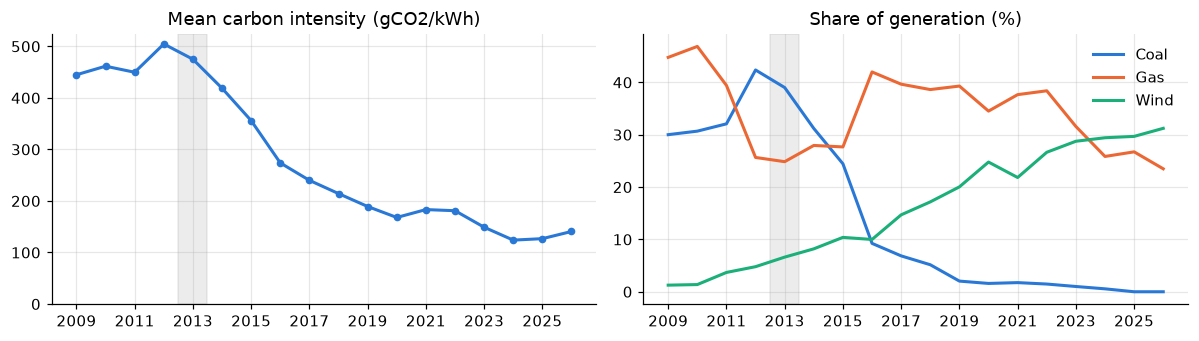

mean CI by year: {2009: 445, 2010: 461, 2011: 450, 2012: 505, 2013: 475, 2014: 419, 2015: 356, 2016: 274, 2017: 240, 2018: 214, 2019: 189, 2020: 168, 2021: 183, 2022: 181, 2023: 149, 2024: 124, 2025: 127, 2026: 141}


In [2]:
yr = df.resample("YE").mean()
share = yr[["COAL", "GAS"]].div(yr.GENERATION, axis=0).mul(100).assign(WIND=(yr.WIND + yr.WIND_EMB) / yr.GENERATION * 100)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(yr.index.year, yr.CARBON_INTENSITY, color=BLUE, marker="o", ms=4)
ax[0].axvspan(2012.5, 2013.5, color="grey", alpha=0.15); ax[0].set(title="Mean carbon intensity (gCO2/kWh)", ylim=(0, None))
for c, col in zip(["COAL", "GAS", "WIND"], [BLUE, ORANGE, AQUA]):
    ax[1].plot(share.index.year, share[c], color=col, label=c.title())
ax[1].axvspan(2012.5, 2013.5, color="grey", alpha=0.15); ax[1].set(title="Share of generation (%)"); ax[1].legend(frameon=False)
for a in ax: a.set_xticks(range(2009, 2027, 2))
plt.tight_layout(); plt.show()
print("mean CI by year:", {y.year: int(v) for y, v in yr.CARBON_INTENSITY.round(0).items()})

**Marginal carbon intensity.** A tariff shifts demand at the margin, so what matters is the CI of the plants that ramp, not the average mix. For each year, marginal CI is the OLS slope of the half-hourly change in emissions (CI × generation) on the change in dispatchable output, i.e. every fuel except wind and solar, which don't respond to demand (Hawkes 2010). Up to 2013 this matches the pipeline's annual estimate (`carbon_tariff_pipeline/scripts/01b_marginal_emissions.py`, which regresses on total generation) to within 8 g/kWh. After 2013 that version lets solar and wind ramps drag the slope down, so dispatchable output is used here. "Share of the margin" is the slope of each fuel's change on the same regressor.

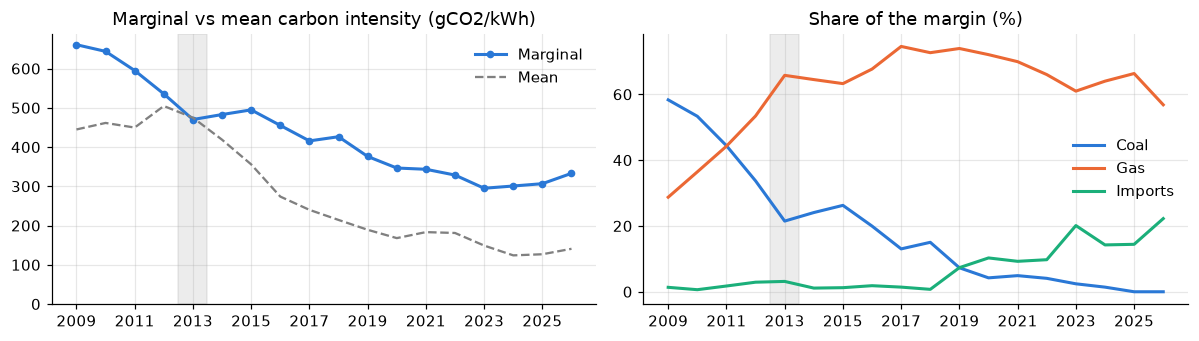

          marginal CI  mean CI    R2  Coal % of margin  Gas % of margin  Imports % of margin
DATETIME                                                                                    
2009              661      445  0.92                58               29                    1
2010              644      461  0.93                53               36                    1
2011              595      450  0.92                44               44                    2
2012              536      505  0.88                34               53                    3
2013              470      475  0.89                21               66                    3
2014              483      419  0.91                24               64                    1
2015              495      356  0.93                26               63                    1
2016              455      274  0.92                20               68                    2
2017              416      240  0.91                13               7

In [3]:
DISP = ["GAS", "COAL", "NUCLEAR", "HYDRO", "IMPORTS", "BIOMASS", "OTHER", "STORAGE"]  # every fuel except wind & solar
step = df.index.to_series().diff() == pd.Timedelta("30min")
dd = df[DISP].diff()[step]
dd["N"] = dd.sum(axis=1)                                      # change in dispatchable output (MW)
dd["E"] = (df.CARBON_INTENSITY * df.GENERATION).diff()[step]  # change in emissions (kg/h)
slope = lambda g, y: np.cov(g.N, g[y])[0, 1] / g.N.var()      # OLS slope, with intercept
mef = dd.groupby(dd.index.year).apply(lambda g: pd.Series({
    "marginal CI": slope(g, "E"), "R2": g.N.corr(g.E) ** 2,
    **{f"{f.title()} % of margin": 100 * slope(g, f) for f in ["COAL", "GAS", "IMPORTS"]}}))
mef.insert(1, "mean CI", df.CARBON_INTENSITY.groupby(df.index.year).mean())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(mef.index, mef["marginal CI"], color=BLUE, marker="o", ms=4, label="Marginal")
ax[0].plot(mef.index, mef["mean CI"], color="grey", ls="--", lw=1.5, label="Mean")
ax[0].set(title="Marginal vs mean carbon intensity (gCO2/kWh)", ylim=(0, None)); ax[0].legend(frameon=False)
for c, col in zip(["Coal", "Gas", "Imports"], [BLUE, ORANGE, AQUA]):
    ax[1].plot(mef.index, mef[f"{c} % of margin"], color=col, label=c)
ax[1].set(title="Share of the margin (%)"); ax[1].legend(frameon=False)
for a in ax: a.axvspan(2012.5, 2013.5, color="grey", alpha=0.15); a.set_xticks(range(2009, 2027, 2))
plt.tight_layout(); plt.show()
print(mef.round(0).astype(int).assign(R2=mef.R2.round(2)).to_string())

## 2. 2013: what drives CI
CI is (almost) a deterministic function of the mix: a no-intercept regression of CI on fuel shares recovers plausible emission factors.

In [4]:
s = df.loc["2013"].copy()
X = s[FUELS].div(s.GENERATION, axis=0)
beta, *_ = np.linalg.lstsq(X.values, s.CARBON_INTENSITY.values, rcond=None)
resid = s.CARBON_INTENSITY - X.values @ beta
print(pd.DataFrame({"mean share %": X.mean().mul(100).round(1), "implied gCO2/kWh": beta.round(0)}).sort_values("mean share %", ascending=False).T.to_string())
print(f"residual sd: {resid.std():.1f} g/kWh (CI sd {s.CARBON_INTENSITY.std():.1f})")
print(s.CARBON_INTENSITY.describe().round(0).to_dict())
print("corr with CI:", s[["COAL_perc", "GAS_perc", "WIND_perc", "GENERATION"]].corrwith(s.CARBON_INTENSITY).round(2).to_dict())

                   COAL    GAS  NUCLEAR  WIND  IMPORTS  OTHER  WIND_EMB  HYDRO  STORAGE  SOLAR  BIOMASS
mean share %       39.1   23.6     21.3   5.9      5.8    1.2       0.9    0.9      0.8    0.6      0.0
implied gCO2/kWh  945.0  394.0     -8.0   5.0    184.0  321.0     -26.0  -23.0      2.0   -7.0      0.0
residual sd: 3.0 g/kWh (CI sd 47.4)
{'count': 17520.0, 'mean': 475.0, 'std': 47.0, 'min': 259.0, '25%': 445.0, '50%': 478.0, '75%': 507.0, 'max': 622.0}
corr with CI: {'COAL_perc': 0.78, 'GAS_perc': 0.2, 'WIND_perc': -0.51, 'GENERATION': 0.37}


## 3. Intraday & seasonal shape (the lever for a carbon-aware tariff)

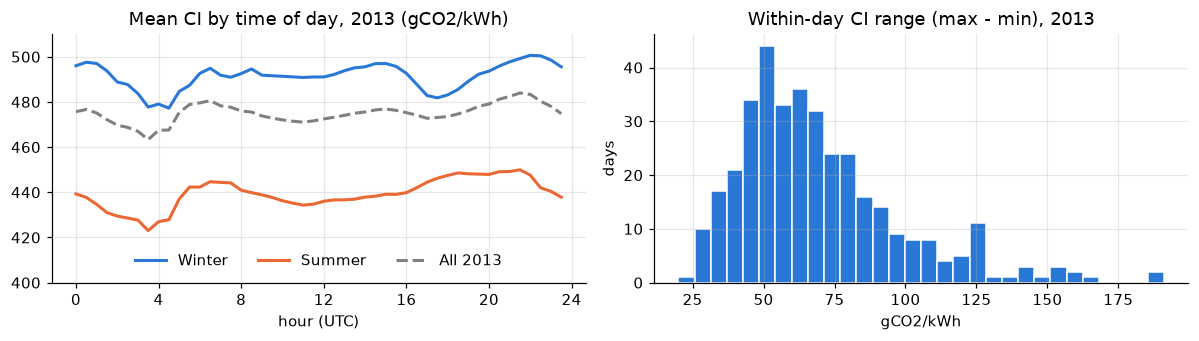

amplitude of the AVERAGE daily profile: 21 g/kWh
median within-day range on a GIVEN day: 64 g/kWh (13% of mean)
sd of daily-mean CI across days: 43 g/kWh
hour (UTC) of the daily minimum, top 5 (% of days): {3: 15, 23: 15, 4: 11, 18: 10, 17: 8}
mean CI by weekday (0=Mon): {0: 471, 1: 481, 2: 483, 3: 484, 4: 482, 5: 468, 6: 456}


In [5]:
s["hh"] = s.index.hour + s.index.minute / 60
season = s.index.month.map({12: "Winter", 1: "Winter", 2: "Winter", 6: "Summer", 7: "Summer", 8: "Summer"})
day = s.CARBON_INTENSITY.resample("D")
rng = day.max() - day.min()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for name, col in [("Winter", BLUE), ("Summer", ORANGE)]:
    ax[0].plot(*s[season == name].groupby("hh").CARBON_INTENSITY.mean().pipe(lambda p: (p.index, p.values)), color=col, label=name)
ax[0].plot(*s.groupby("hh").CARBON_INTENSITY.mean().pipe(lambda p: (p.index, p.values)), color="grey", ls="--", label="All 2013")
ax[0].set(title="Mean CI by time of day, 2013 (gCO2/kWh)", xlabel="hour (UTC)", xticks=range(0, 25, 4), ylim=(400, 510))
ax[0].legend(frameon=False, ncol=3, loc="lower center")
ax[1].hist(rng, bins=30, color=BLUE, edgecolor="white")
ax[1].set(title="Within-day CI range (max - min), 2013", xlabel="gCO2/kWh", ylabel="days")
plt.tight_layout(); plt.show()
prof = s.groupby("hh").CARBON_INTENSITY.mean()
argmin = day.apply(lambda x: x.idxmin().hour)
print(f"amplitude of the AVERAGE daily profile: {prof.max() - prof.min():.0f} g/kWh")
print(f"median within-day range on a GIVEN day: {rng.median():.0f} g/kWh ({rng.median() / s.CARBON_INTENSITY.mean():.0%} of mean)")
print(f"sd of daily-mean CI across days: {day.mean().std():.0f} g/kWh")
print("hour (UTC) of the daily minimum, top 5 (% of days):", argmin.value_counts(normalize=True).mul(100).round(0).head(5).astype(int).to_dict())
print("mean CI by weekday (0=Mon):", s.groupby(s.index.dayofweek).CARBON_INTENSITY.mean().round(0).astype(int).to_dict())

## 4. Forecastability: naive baselines to beat in Step 1

In [6]:
ci = df.CARBON_INTENSITY
ev = ci["2013"]
print("autocorrelation (2013):", {f"lag {k}": round(float(ev.autocorr(k)), 2) for k in [1, 48, 96, 336]})
rows = {}
for name, lag in [("same slot, 1 day ago", 48), ("same slot, 2 days ago", 96), ("same slot, 1 week ago", 336)]:
    e = (ev - ci.shift(lag).reindex(ev.index)).dropna()
    rows[name] = {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean())}
print(pd.DataFrame(rows).T.round(1).to_string())

autocorrelation (2013): {'lag 1': 0.99, 'lag 48': 0.74, 'lag 96': 0.6, 'lag 336': 0.54}
                        MAE  RMSE
same slot, 1 day ago   24.4  33.9
same slot, 2 days ago  30.9  42.5
same slot, 1 week ago  34.1  45.8


## 5. Does the historical 2013 tariff follow carbon intensity?
`Tariffs.xlsx` (needs `openpyxl`). Its timestamps are **London clock time** (checked against LCL consumption in `CVAE_reproduction/`), so they are converted to UTC first. CI is measured relative to each day's mean to remove the seasonal level. The *carbon-aware* column keeps each day's number of High/Low slots but puts them on that day's dirtiest/cleanest half-hours (perfect-foresight upper bound).

In [7]:
tar = pd.read_excel("Tariffs.xlsx", usecols=["TariffDateTime", "Tariff"]).set_index("TariffDateTime").Tariff
utc = tar.index.tz_localize("Europe/London", ambiguous="NaT", nonexistent="NaT").tz_convert("UTC").tz_localize(None)
tar = pd.Series(tar.to_numpy(), index=utc, name="Tariff")[utc.notna()]  # drops the 2 nonexistent + 2 ambiguous clock slots
s = df.loc["2013", ["CARBON_INTENSITY"]].join(tar, how="inner")
d = s.index.date
s["dev"] = s.CARBON_INTENSITY - s.groupby(d).CARBON_INTENSITY.transform("mean")
nH = (s.Tariff == "High").groupby(d).transform("sum")
nL = (s.Tariff == "Low").groupby(d).transform("sum")
r = s.groupby(d).CARBON_INTENSITY.rank(method="first")  # 1 = cleanest slot of the day
s["carbon_aware"] = np.where(r > 48 - nH, "High", np.where(r <= nL, "Low", "Normal"))
print(f"{len(s):,} half-hours joined |", s.Tariff.value_counts().to_dict())
print(pd.DataFrame({"actual": s.groupby("Tariff").dev.mean(),
                    "carbon-aware": s.groupby("carbon_aware").dev.mean()}).round(1)
      .rename_axis("CI vs day mean (g/kWh)").to_string())
g = s.groupby([d, "Tariff"]).CARBON_INTENSITY.mean().unstack().dropna(subset=["High", "Low"])
print(f"days with both High and Low slots: {len(g)}; High slots dirtier than Low on {(g.High > g.Low).mean():.0%} of them")
print("hours (UTC) with most High slots:", s[s.Tariff == "High"].index.hour.value_counts().head(6).sort_index().index.tolist())

17,516 half-hours joined | {'Normal': 15068, 'Low': 1660, 'High': 788}
                        actual  carbon-aware
CI vs day mean (g/kWh)                      
High                      -2.5          23.0
Low                        1.1         -16.9
Normal                     0.0           0.7
days with both High and Low slots: 28; High slots dirtier than Low on 46% of them
hours (UTC) with most High slots: [17, 18, 19, 20, 21, 22]


## Takeaways
- **Clean data.** 2009-01 → 2026-10, 30-min, no NaNs/gaps/duplicates; fuels sum to `GENERATION`. Only issues: one Dec-2025 block stored out of order (**sort on load**) and `ZERO_CARBON_perc` disagrees with `ZERO_CARBON / GENERATION` (up to 8 pts in 2013, 69 pts later) (**don't use it**; rebuild shares from fuel columns). `BIOMASS` is 0 in 2013 (not reported separately then).
- **Time zone.** Continuous 30-min grid through every DST change ⇒ timestamps are UTC (as NESO's data dictionary says; it does not say whether a label is the start or the end of the half-hour). LCL `DateTime` is GMT but labels the **end** of each half-hour; `Tariffs.xlsx` is **London clock time** (start-labelled). Convert both before joining (section 5 does this for the tariffs).
- **Regime shift.** Mean CI fell from ~475 (2013) to ~130 g/kWh (2025); 2013 is coal-dominated. **Train the CI forecaster on 2009–2013 only**; post-2013 data is both a different regime and future information.
- **CI ≈ mix.** In 2013 CI is a near-exact linear function of fuel shares (coal ≈ 950, gas ≈ 390 g/kWh). Forecasting CI ≈ forecasting coal/gas vs. wind/nuclear shares; same-time mix columns are leakage, only **lagged** mix is a valid feature.
- **No fixed low-carbon window in 2013.** On a given day CI spans ~64 g/kWh (~13% of the mean), but the *average* time-of-day profile is nearly flat (~20 g/kWh; slightly cleaner ~03:00, dirtier ~21:00 UTC). The cleanest half-hours move from day to day, so a fixed TOU schedule cannot track them. This supports a forecast-driven daily tariff, which is the policy-tree design. Season (winter ≈ 50 g/kWh above summer) and weekends (≈ 20 lower) shift the level more than time of day does, so calendar features matter.
- **Upper bound on gains.** Moving 1 kWh from the dirtiest to the cleanest slot saves ~13% of its emissions on a typical day; total reductions will be well below that because only part of the load shifts.
- **Baseline and difficulty.** Persistence MAE is 24 g/kWh (same slot, 1 day ago) or 31 g/kWh (2 days ago, the honest baseline if tariffs are announced before day *d−1* ends). That error is a third to half of the within-day range, so also score Step 1 on whether it **ranks** each day's low/high slots correctly, not just on MAE.
- **The 2013 tariff ignores carbon intensity.** High slots (mostly 17:00-22:00, the demand peak) were on average slightly *cleaner* than their day's mean and Low slots slightly dirtier; on days with both, High was dirtier than Low only about half the time. Re-placing the same number of High/Low slots on each day's dirtiest/cleanest half-hours would give High slots ≈ 40 g/kWh more CI than Low slots (vs ≈ −4 historically). That is the headroom this project targets; a real forecast will capture only part of it.